# Group 5: Do trains, ships and events move the crowds? A crowd monitoring dashboard for SAIL Amsterdam 2025

*TIL6022 Python Programming, final report, 6 November 2026*

Members:
- Davide Pighin (GitHub: `Dpighin`)
- Andrea Della Corte (GitHub: `andreadellacorte3`)
- Daniele Bini (GitHub: `Danielebini27`)
- Roberto Cortes Camilo De Sales (GitHub: `cortesjose36-png`)
- Mateo Gonzalez (GitHub: `mateogonzalezbrown`)

# Introduction

In 2010, 21 people died in a crowd crush at the Love Parade in Duisburg. In 2022, 159 people died in a narrow street in Itaewon, Seoul. In both cases the danger appeared in minutes, in a place that was not expected to be critical. Every large event carries this risk, and SAIL in Amsterdam is one of the largest: in August 2025 more than 2.5 million visitors and 10,000 ships came to the IJ in five days.

To watch the crowds, the City of Amsterdam counted pedestrians with 37 sensors around the IJ, every three minutes and in both walking directions. Yet a count on its own does not tell a crowd manager what to do or how to interpret it. A sensor showing zero can mean an empty street, a broken sensor, or a ferry that has stopped running. A sudden peak can be a train emptying onto the square, which is gone in minutes, or a crowd gathering for a parade, which keeps growing. To act on the numbers, the crowd manager needs to know what was happening around them.

Around the IJ, three things move the crowds: trains bring visitors to Amsterdam Centraal, ships draw them to the water, and the SAIL programme tells them where to be and when. This leads to our research question: *to what extent are trains, vessels and SAIL events affecting the pedestrian counts around the IJ during SAIL 2025?*

To answer it, we analysed the pedestrian counts of SAIL 2025 together with the train arrivals, the vessel positions and the complete event programme, and we built a dashboard that replays the five days minute by minute, as a crowd manager would have seen them live. With the previous edition ten years earlier and the next one planned for 2030, the lessons from this replay are meant to support better decisions for the next SAIL.

The report follows the path a crowd manager would take. We first check whether the sensors can be trusted (SQ1), then find where and when the crowds came closest to critical levels (SQ2), and then ask why, looking at events (SQ3), trains (SQ4) and vessels (SQ5). Finally, we show how the dashboard brings these results together in one view.

The answer is less simple than "more trains, ships or events means more people". Train arrivals hardly explain the peaks near Amsterdam Centraal: during the day a train arrives every minute and a half, and the sensors see a steady stream rather than separate waves. The events and ships on the water matter most, but not only as peaks: visitors gather before a parade, stand still while the ships pass, when the sensors go quiet and even a ferry can stop, and start walking all at once afterwards. For a crowd manager, this means that a quiet sensor during a parade is not always good news, and that the end of the parade is the critical moment.

# Research Question

The main research question of this project is:

*To what extent are trains, vessels and SAIL events affecting the pedestrian counts around the IJ during SAIL 2025?*

We answer it in the order a crowd manager would work: first check that the data can be trusted, then find where the crowds were, and then look for what caused them.

1. **SQ1 – Can we trust the sensors?** Which sensors stopped working, and how can a broken sensor be told apart from an empty street?
2. **SQ2 – Where and when was it busiest?** Which locations came closest to critical conditions, and at what times?
3. **SQ3 – Do SAIL events explain the peaks?** Were the places near an event busier than on a normal SAIL day at the same time?
4. **SQ4 – Do trains explain the peaks?** Do train arrivals at Amsterdam Centraal lead to more pedestrians near the station?
5. **SQ5 – Do vessels explain the peaks?** Is there a relation between the ships on the IJ and the pedestrian counts?

**How the question changed.** After the proposal and the midterm presentation we narrowed the scope to three factors that belong to the event itself, and for which we had data for all five days: trains, vessels and the SAIL programme.

**Scale.** The study covers the area around the IJ where the sensors are placed, about 4 km by 3 km: the walkways and ferry landings behind Amsterdam Centraal, the banks of the IJ and part of the old city centre. In time, it covers the five days of SAIL 2025, 20 to 24 August 2025, in intervals of 3 minutes.

# Contribution Statement

All members took part in the conceptual design of the dashboard (problem definition, requirements, user stories and design alternatives), chose the research question together, and reviewed each other's work through pull requests on GitHub.

- **Davide Pighin**: built the dashboard (`streamlit_dashboard_initialization.py`): map of the sensors, date and time selection, play and stop buttons, tooltips, table of the running events and the crowd count visualisation. Wrote the loading of the sensor data and optimised the loading of the vessel data.  [🔴🔴TO DO check and complete🔴🔴]

- **Roberto Cortes Camilo De Sales**: helped frame the dashboard from the point of the crowd manager. Translated that into key insights to build the research question, the analysis and the storyline. Built the reference data that connect the counts to the event: the SAIL 2025 programme catalogue and the event locations from sail.nl, the grouping of the sensors into zones and the links between events and zones (`data/external/`). Wrote the conversion of counts into flow per metre (`src/flow.py`), the event functions and its analysis (`src/events.py`, `src/event_plots.py`), added the day overview analysis.

- **Daniele Bini**: prepared the vessel data and built the first vessel layer of the dashboard (SQ5), mapped the sensors to their coordinates for the station analysis, helpedcmateo filtering data, and added the count of flow alarms per sensor to the dashboard. [🔴🔴TO DO check and complete🔴🔴]

- **Andrea Della Corte**: set up the repository and the project proposal (notebook, exports and README). Collected the train arrivals and departures at Amsterdam Centraal (`src/trains.py`), counted the pedestrians at the station sensors (`src/station_sensors.py`) and analysed the relation between trains and pedestrians (`src/train_effect.py`, SQ4). Detection of sensors that are off and levels of service (`src/sensor_status.py`). [🔴🔴TO DO check and complete🔴🔴]

- **Mateo Gonzalez**: explored and cleaned the datasets (`Data_Transformation.ipynb`): checked the sensor counts for missing values and zeros, filtered the SAIL ships out of the vessel data, and joined the TomTom traffic data to the NWB road network.

# Data Used

We combine the data provided by the course lecturers with reference tables we made ourselves and with open data. The table below gives an overview; the sections after it describe each source.

| Dataset | Type | Source | Used in |
|---|---|---|---|
| Pedestrian counts, 3-min intervals | Provided | LVMA sensor network, City of Amsterdam | All SQs, dashboard |
| Sensor locations and widths | Provided | City of Amsterdam | All SQs, dashboard |
| Vessel positions (AIS) | Provided | Course data | SQ5, dashboard |
| SAIL 2025 programme | Made by us | sail.nl | SQ3, dashboard |
| Event locations | Made by us | sail.nl | SQ3 |
| Sensor zones | Made by us | Sensor locations | SQ3, dashboard |
| Event–zone links | Made by us | Event locations and sensor zones | SQ3 |
| Train arrivals and departures | Open data | Rijden de Treinen | SQ4, dashboard |
| Car traffic and road network | Provided | TomTom, NWB | Explored, not used |

## Provided by the course

**Pedestrian counts** (`SAIL2025_LVMA_data_3min_20August-25August2025_flow.csv`). Counts of the LVMA network (*Langzaam Verkeer Monitoringssysteem Amsterdam*) of the City of Amsterdam: 37 sensors around the IJ, each counting both walking directions, in intervals of 3 minutes from 20 to 24 August 2025, which gives 2,400 intervals per direction. The sensors belong to three families: walkways set up for SAIL (GASA), ferry landings (GVCV) and streets in the city centre (CMSA and GACM).

**Sensor locations** (`sensor-location.xlsx`). Name, location, coordinates, width and effective width of each sensor. The effective width is what we use to turn counts into flow per metre. One sensor of the counts (GASA-06-B) has no location in this file.

**Vessel positions** (`Vesselposition_data_20-24Aug2025.csv`). AIS positions of the ships on and around the IJ, about every minute. The file holds thousands of vessels, most of them not related to SAIL (cargo ships, tugs, port services), so we kept only the ships of the SAIL fleet, using their type and destination. [🔴🔴TO DO final number of ships and the time covered🔴🔴]

**Car traffic and road network** (`TomTom_data_20-24Aug2025.csv`, `NWB_roads.zip`). Speeds and flows of car traffic per road segment, which can be joined to the national road network (NWB). We prepared and joined both files, but did not use them in the analysis, because car traffic is outside the three factors of our research question.

## Made by us

These four files are in `data/external/` and are public. They contain our own choices and were made based on assumptions of our own criteria, so we wrote them down as data instead of hiding them in the code, where they can be checked and changed.

**SAIL 2025 programme** (`sail2025_program.csv`). The official daily programme, transcribed from sail.nl: 85 time slots of 26 events, each with date, start and end time and one of five types (ship parade, crew parade, evening show, stage and activity).

**Event locations** (`sail2025_event_locations.csv`). The place of each event, as published on its page on sail.nl.

**Sensor zones** (`sensor_zones.csv`). The 36 sensors with a location are grouped into 14 zones with three rules: ferry landings by destination (for example, the landing at Central Station towards NDSM), walkways near Central Station by their position, and the other sensors by neighbourhood. We checked the zones visually on a map (`check_zones.py`).

**Event–zone links** (`event_zone_links.csv`). For each event, the zones it is expected to affect and how: the event takes place *at* the zone, *near* it, along its *route*, or the zone gives *access* to it. Each link has a confidence level and a short note.

## Open data

**Train services** (`services-2025-08.csv.gz`). The open train archive of Rijden de Treinen, with every stop of every train in the Netherlands in August 2025. The code downloads it, keeps the stops at Amsterdam Centraal, removes cancelled stops and replacement buses, and counts the arrivals and departures per 3 minutes, at their actual time (planned time plus delay).

## Data handling

The course data are not in the repository: the teaching team asked us not to upload them, and some files are larger than GitHub allows. The README explains where to place them to run this notebook🔴🔴🔴. All counts are aggregated per sensor and per 3 minutes, so no visitor can be identified.

# Data Pipeline

The pipeline goes from the raw files to the answers of the sub-questions and to the dashboard. The code is split into small modules in `src/`, so that this notebook and the dashboard use the same functions.

| Step | What happens | Code | Used in |
|---|---|---|---|
| 1. Load | Read the counts, the sensor locations and the SAIL programme | `src/events.py`, `Population_of_dictionary_with_pedestrian_data.py` | All |
| 2. Clean | Add up the two walking directions of each sensor; mark a sensor as off when it reports zero for at least one hour while similar sensors still count people | `src/events.py`, `src/sensor_status.py` | SQ1 |
| 3. Transform | Divide the counts by the effective width and by 3 minutes, to get persons per metre per minute; translate this flow into the levels of service A–F of Fruin (1971) | `src/flow.py`, `src/sensor_status.py` | SQ2 |
| 4. Add context | Group the sensors into zones and link them to the events; count the trains at Amsterdam Centraal per 3 minutes; keep the positions of the SAIL ships | `src/events.py`, `src/trains.py`, [🔴🔴🔴TO DO – vesselsTranslated that need into the research question, the analysis and the storyline of the midterm presentation and of this report, which he structured and wrote.🔴🔴🔴] | SQ3–SQ5 |
| 5. Analyse | Compare each event day with the other SAIL days; relate train arrivals to the pedestrians near the station; [🔴🔴🔴TO DO – vessels🔴🔴🔴] | `src/events.py`, `src/train_effect.py`, [🔴🔴TO DO]🔴🔴 | SQ3–SQ5 |
| 6. Show | Figures in this notebook, and the dashboard that replays the five days on a map | `src/event_plots.py`, `streamlit_dashboard_initialization.py` | All |

Every step only reads the output of the step before it, so a change in one step (for example a different threshold) runs through the whole analysis without changing the other steps.

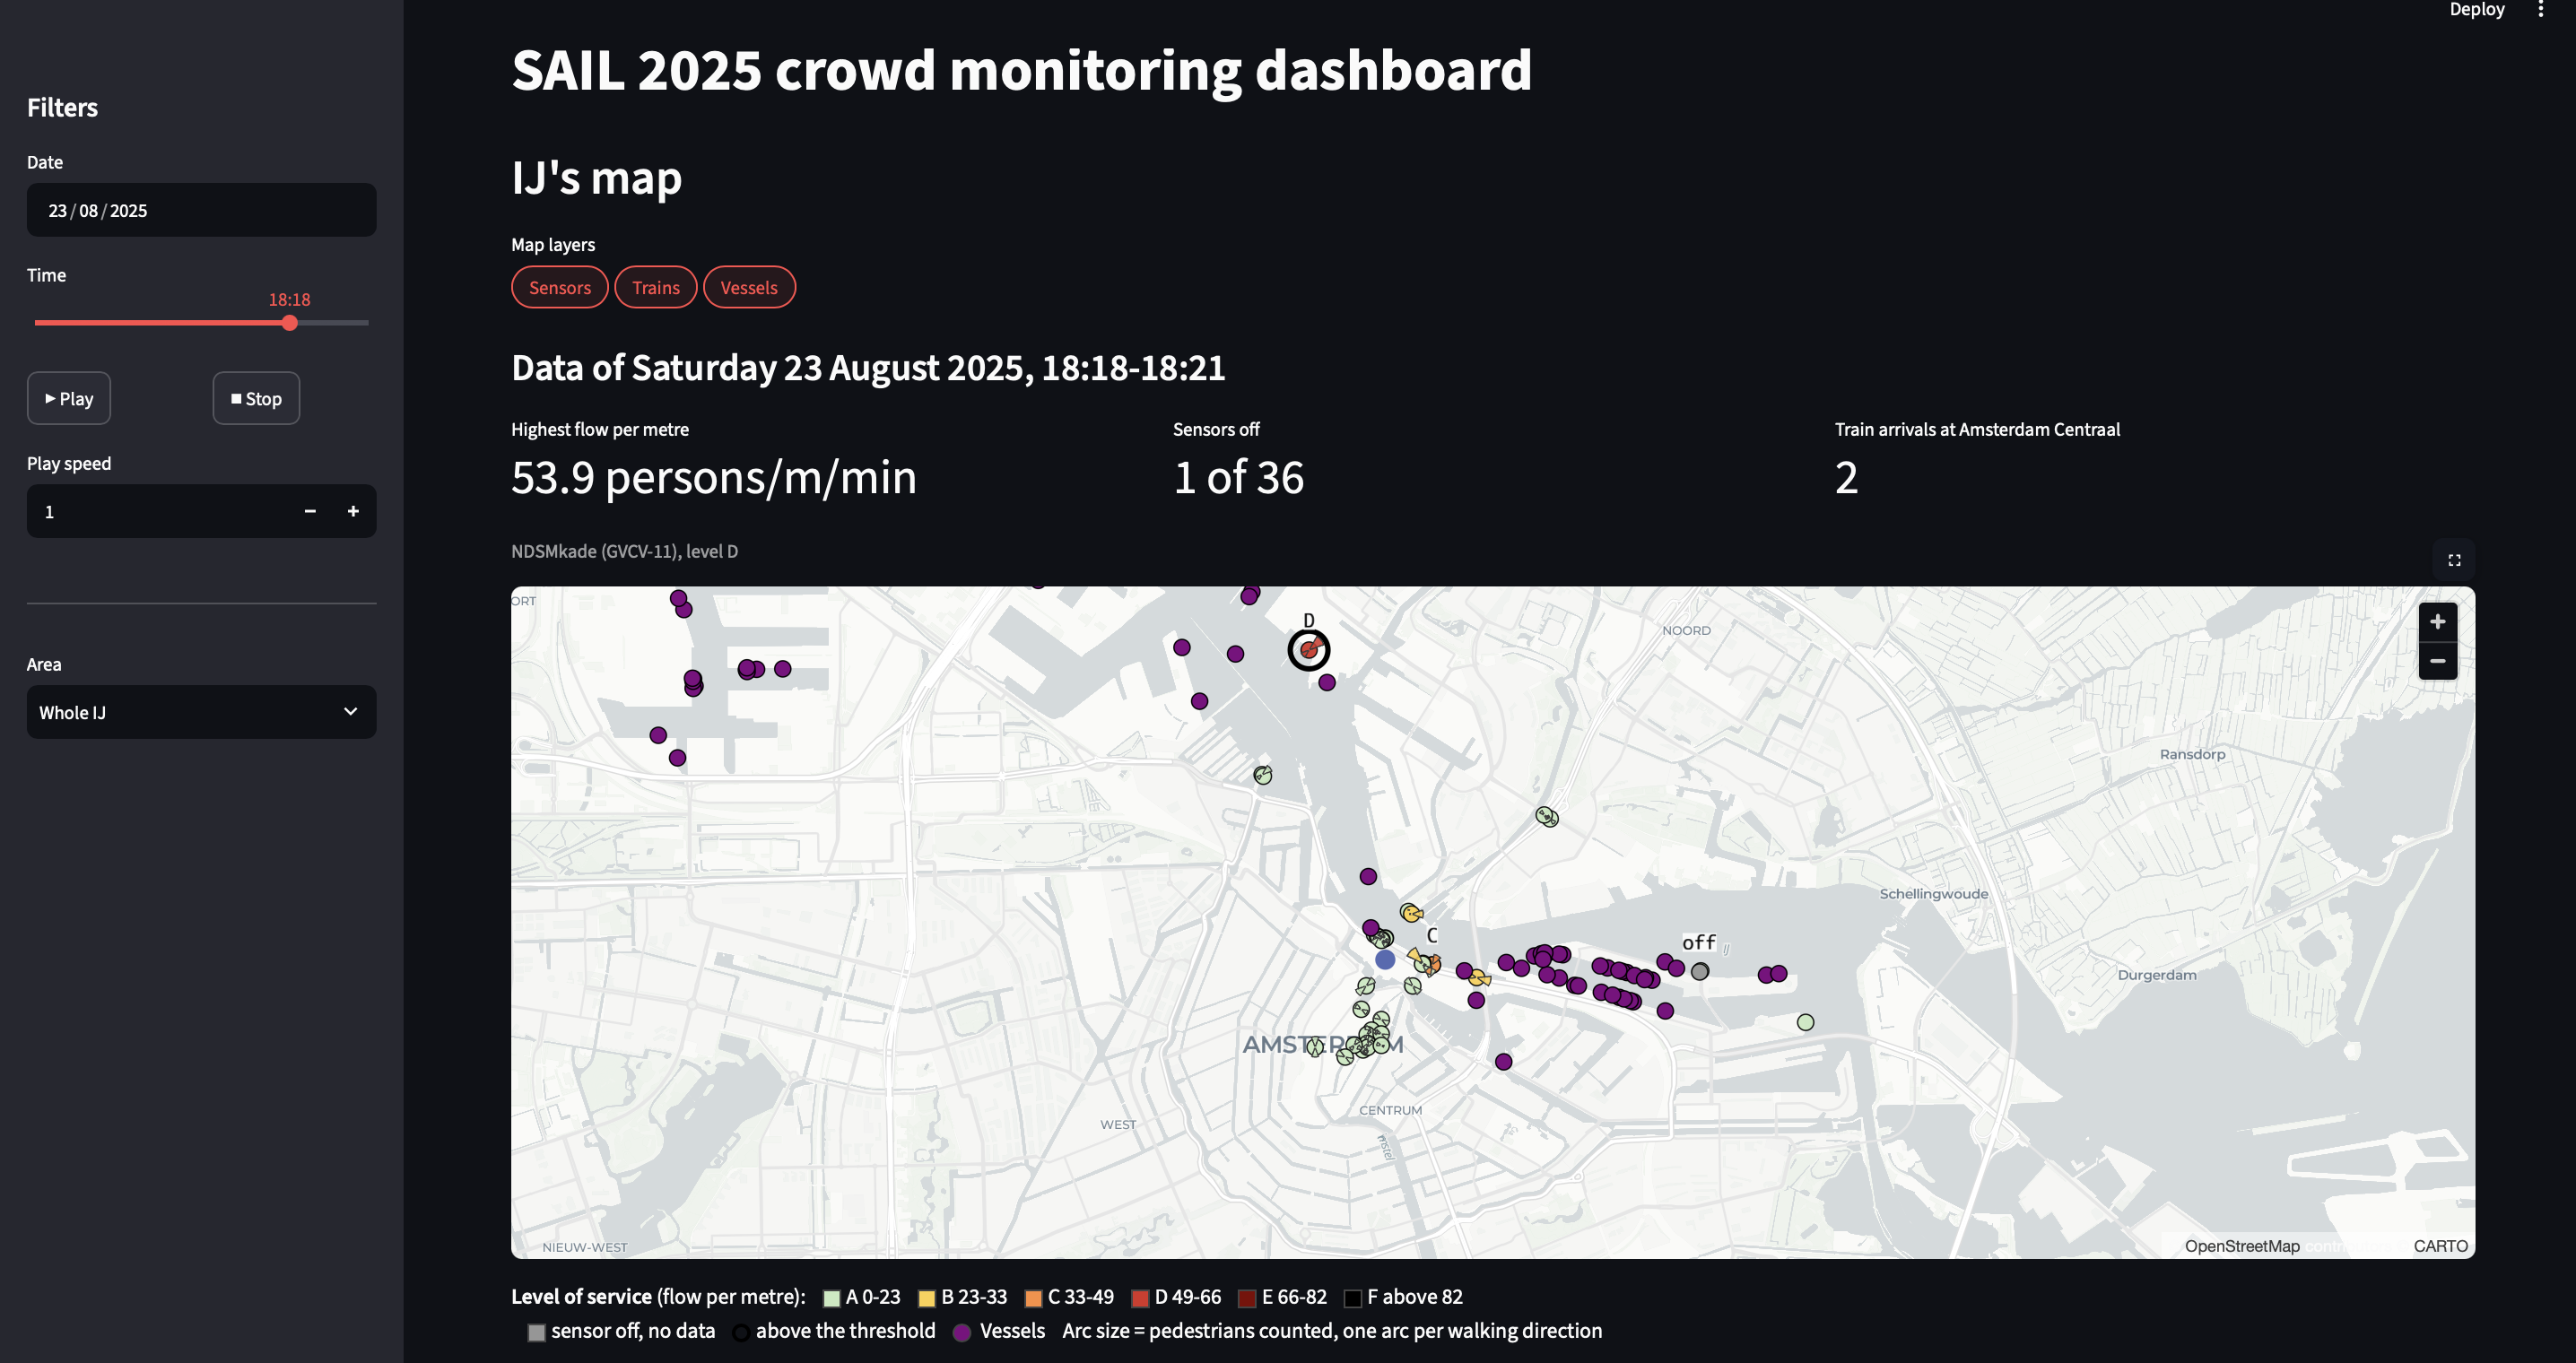


The interactive dashboard is designed to support crowd safety at future SAIL events by analyzing SAIL 2025. The dashboard itself addresses the five subquestions:

•SQ1: Can we trust a sensor?

•SQ2: Where and when was the busiest moment/day?

•SQ3: Do SAIL events explain the peaks?

•SQ4: Do trains explain the peaks?

•SQ5: Do vessels explain the peaks?

The interface itself is structured into two modules: the Interactive Map & Control and the Analytics Module.


**Interactive map and control**

This section provides an interactive map of the IJ, enabling the operator to isolate the following layers and customize their display through temporal and spatial filters:

**Top bar:** 

The top bar panel provides summary metrics for the selected time slice (3 minutes) in the dashboard:
    
Highest flow per metre: Displays the peak pedestrian density rate registered across the entire network (e.g., 29.5 persons/m/min), indicating the exact sensor code/location (e.g., Buiksloterweg [GVCV-13]) and its Level of service grade (level B). (SQ2: Where and when was it busiest?)

Sensors off: Counts the offline sensors out of the total nodes. (SQ1: Can we trust a sensor?) 

Train arrivals at Amsterdam Centraal: Indicates the number of people arriving by train at the station during the active 3-minute window. (SQ4: Do trains explain the peaks?) 



The interactive map presents the following visual features:

**Clickable layers:**

•Sensors: 37 bidirectional sensors across the entire IJ area whose size changes with the count

•Trains: A dynamic blue circle that changes in size in relation to the number of people arriving by train at Amsterdam Centraal station

•Vessels: 96 main vessels positioned along walkways of the IJ


**Map canvas:**

Map navigation controls allow the operator to drag across the view, as well as zoom in and out using the + and - buttons.

Legend:

•Level of Service: Different colored dots and overlays indicating crowd density on a scale from A to F (A [0-23], B [23-33], C [33-49], D [49-66], E [66-82], F [above 82]).

•Thresholds: Black critical circles show locations exceeding density limits.

•Vessels: Display vessels locations. (SQ5: Do vessels explain the peaks?)

•Offline sensor Markers: Highlight dead nodes to inform operators of faulty sensors. (SQ1: Can we trust a sensor?)


**Sidebar:**


•Date selector: Allows the operator to choose any single day from the 20 to 24 of August 2025, recalculating data for each sensor in the area.

•Time slider: Allows the operator to select a 3 minute range period for all the 24 hours of the day selected in the date selector; dragging the slider updates the map overlays for that specific time window.

•Playback buttons: Automate the time slider replay and allowing the operator to choose different speed for the playback

•Speed button: Adjust the playback speed of the simulation allowing the operator to choose different speeds

•Area filter dropdown: Restricts data recalculations and map visual features to specific geographic zones









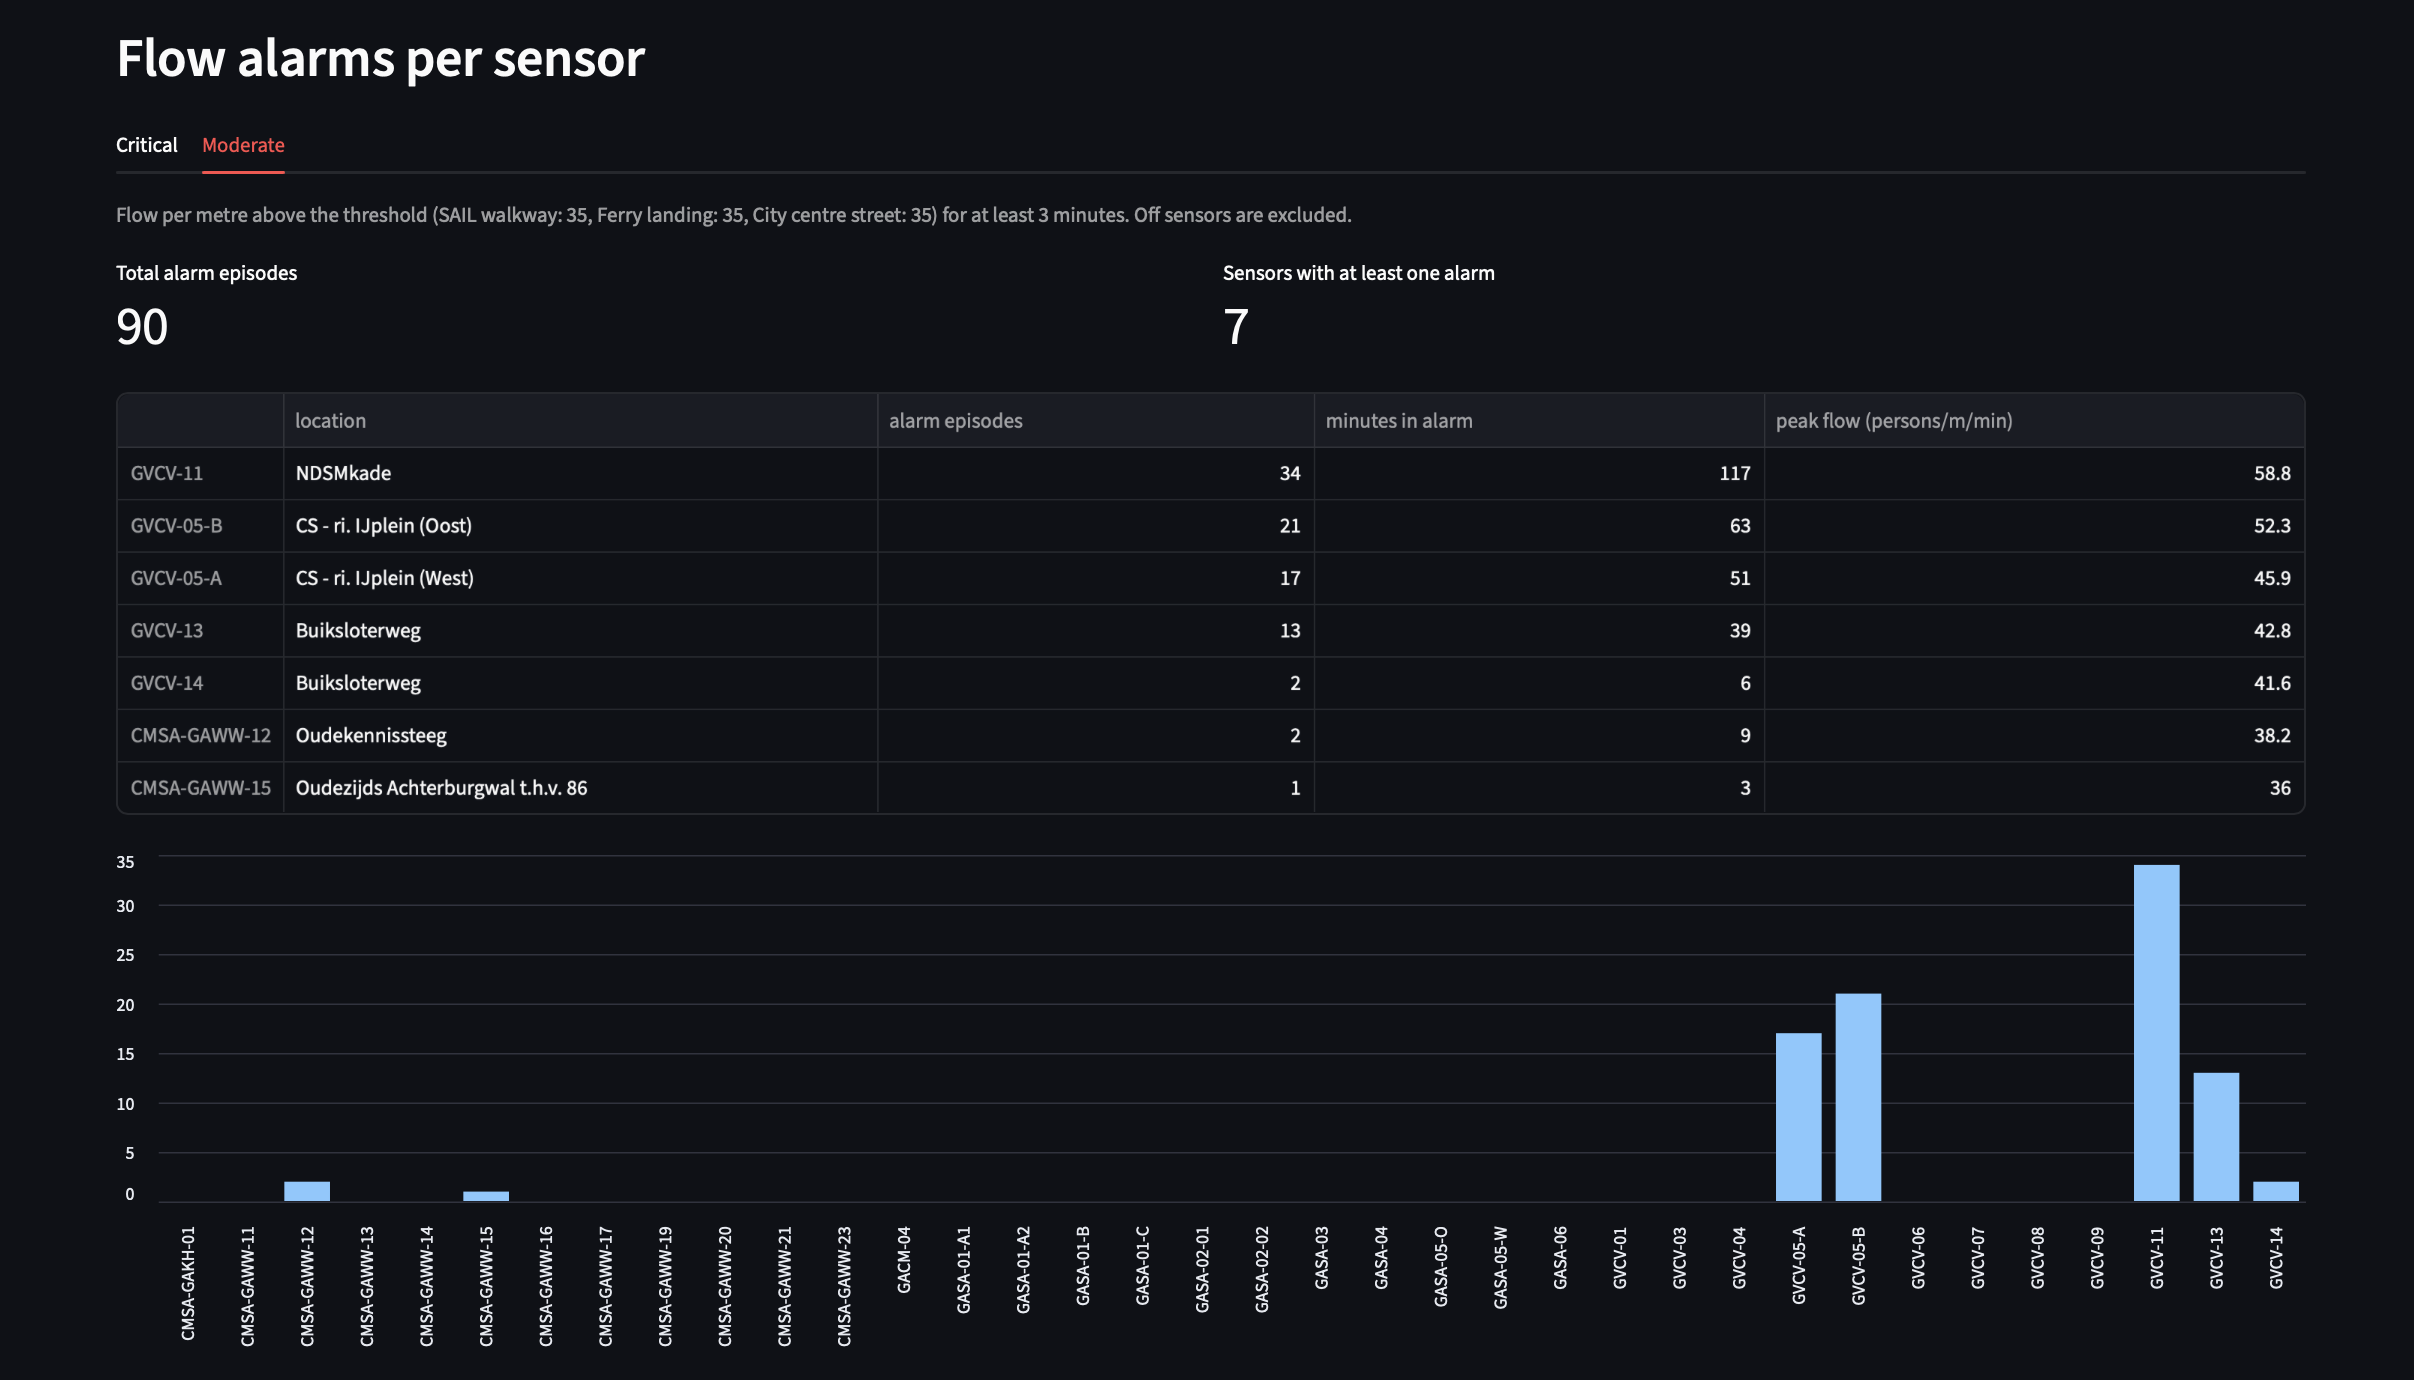

Flow Alarms per Sensor Section Analysis

This section of the dashoard collect the data about sensors which pass the threshold 49 for the critical and 35 or moderate allarms, the main functionalities are:

Filter (Critical / Moderate):

KPI:

    Number of total alarm episodes

    Number of the sensors which registered at least one alarm

    Name of the sensor which registered at least an alarm

    Location of the sensor which registered at least one alarm

    Number of episodes per sensor which registered at least one alarm

    Highest peak flow per sensor which registered at least one alarm



     




# SQ1 – Can we trust the sensors?
In crowd monitoring, data accuracy is essential for public safety. One of the main risks in relying on a digital dashboard is that sensors might experience technical issues and stop counting pedestrians without the crowd manager immediately noticing. If the system fails to identify these inactive sensors, it could lead to an underestimation of crowd sizes in critical areas, creating potentially dangerous situations.


To prevent this, the dashboard is designed to actively recognize and highlight when a sensor stops transmitting data by displaying an "off-tag" on the interface as is shown in the picture.

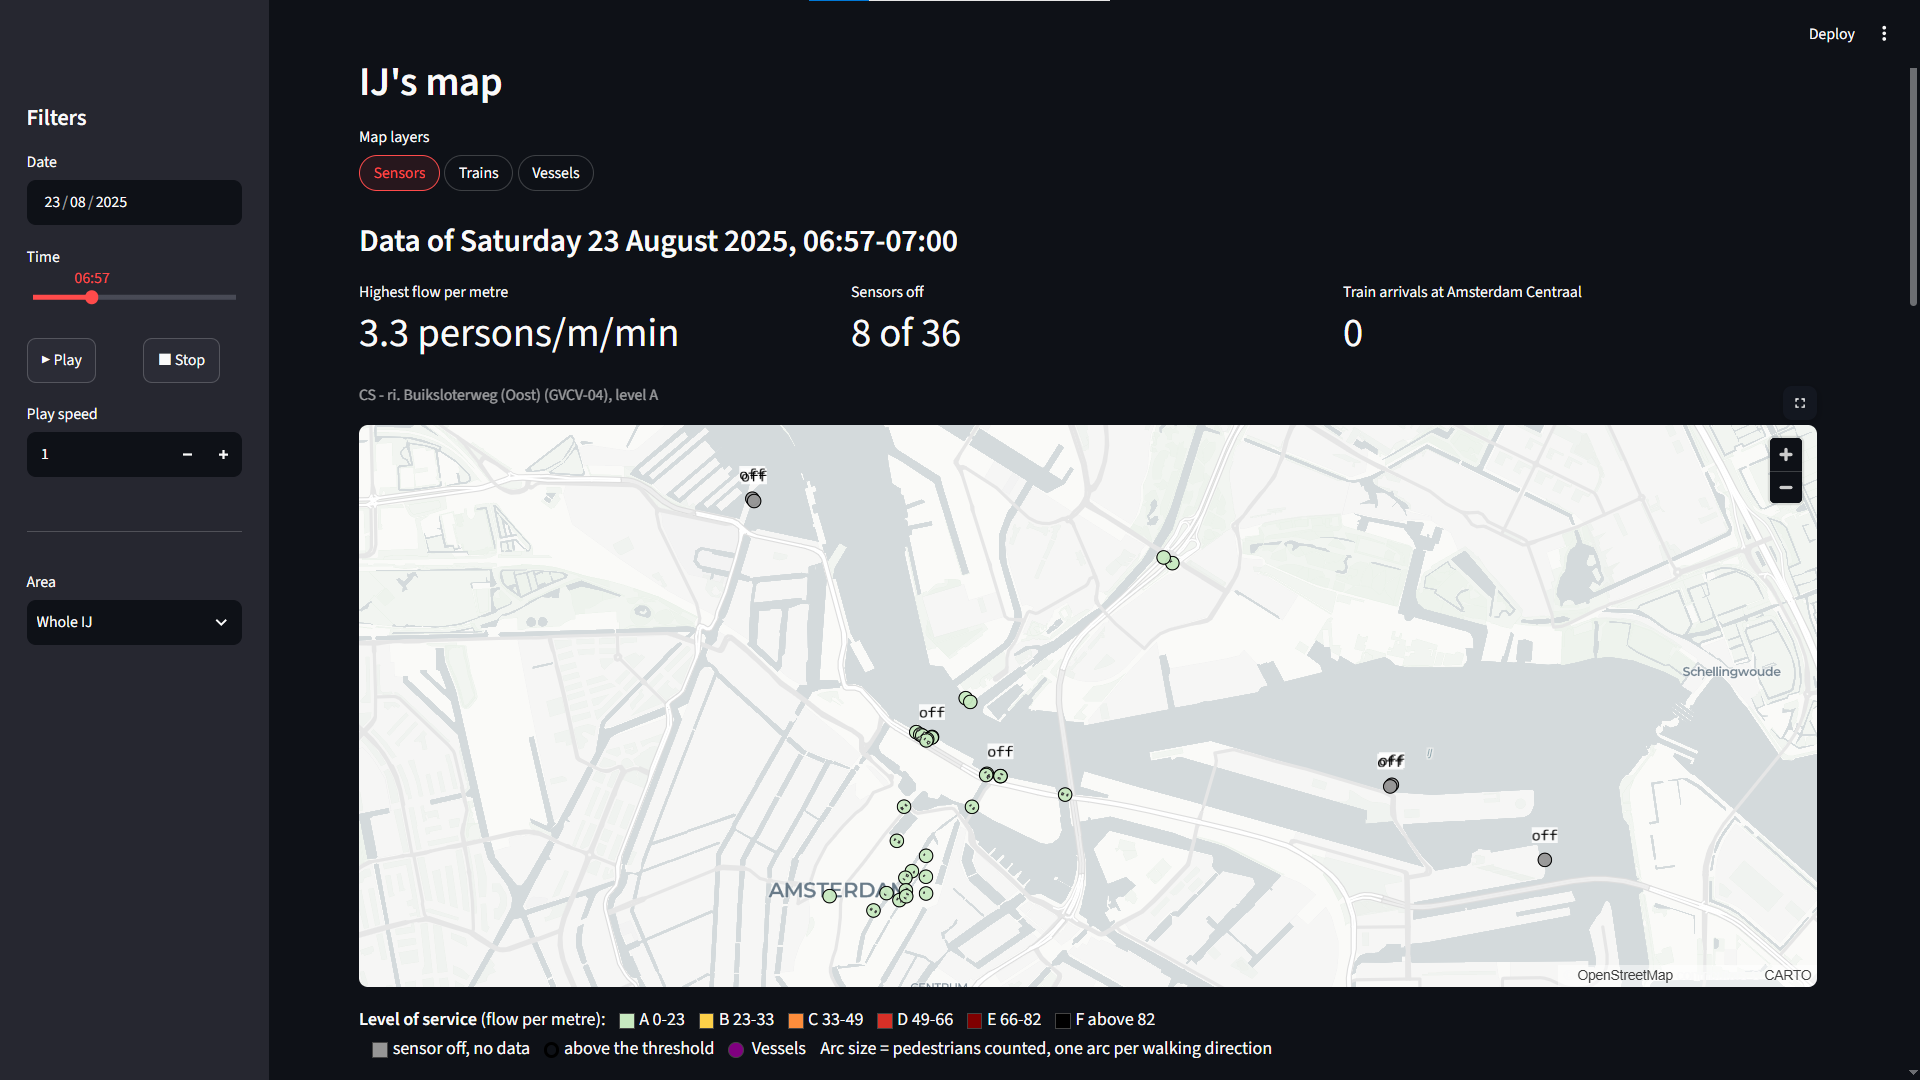


The logic for this feature is implemented in the ``src/sensor_status.py`` file using a straightforward rule-based approach.  




In [ ]:
import pandas as pd
def find_off_sensors(totals, sensors, min_intervals=20):
    off = pd.DataFrame(False, index=totals.index, columns=totals.columns)
    for sensor in totals.columns:
        family = sensors.loc[sensor, "family_description"]
        similar = [s for s in totals.columns
                    if s != sensor and sensors.loc[s, "family_description"] == family]
        others_counting = totals[similar].sum(axis=1) > 0

        zero = totals[sensor] == 0
        run = (zero != zero.shift()).cumsum()     # every run of zeros gets its own number
        for _, period in zero[zero].groupby(run[zero]):
            if len(period) >= min_intervals and others_counting[period.index].any():
                off.loc[period.index, sensor] = True
    return off

Specifically, a sensor is classified as offline if it registers a pedestrian count of zero for 20 consecutive 3-minute time intervals. Requiring 20 consecutive zero-count intervals ensures that the system does not mistakenly flag a working sensor during a temporary lull in foot traffic. This continuous threshold provides a reliable way to distinguish between normal quiet periods and actual technical failures, ensuring that the crowd management team always has an accurate understanding of the sensor network's operational status.

This leads to the conclusion that sensors are reliable for the most part with few exeptions:
- Sensor GASA06 in Azartplein B is off from wednesday to sunday
- Sensor GVCV09 in Zeeburg is also frequently turned off

These sensors are away from the city center and therefore the risk associated to them being off is low.

# SQ2 – Where and when was it busiest?

# SQ3 – Do SAIL events explain the peaks?

The last subquestion showed where and when the crowds were largest. This subquestion is focused on the why, specifically for the events. The SAIL programme placed parades, shows and stages at fixed times, places and zones of the city, so if an event attracts people, the sensors near it should count more people than on a normal SAIL day at the same time.

In the official programme page (sail.nl) the time and place of every event is stated. We linked each event to the zones of sensors it was expected to affect in a catalogue. Then, for each event and zone, we compared the day of the event with the other four SAIL days at the same clock time, and ranked the five days: if an event had no effect, its day would be the most unusual one only one time in five. The analysis is in `src/events.py` (functions `zone_flow` and `event_effect`) and the figures in `src/event_plots.py`; the same functions feed the event section of the dashboard (`src/event_impact.py`).

This test only works for events that took place on a single day. An event that runs every day, such as the stages or the evening shows, has no "normal" day to compare with. With data from days outside SAIL, these events could be tested too.

The core of the comparison, simplified from `event_effect` in `src/events.py`, is four steps for each event and zone:

```python
# 1. Scale each day to its own level: 100% = the average moment of that day (10:00-22:00)
relative[day] = flow_of_day / flow_of_day.between_time("10:00", "21:57").mean()

# 2. Smooth over 30 minutes (10 intervals of 3 min), because ferries count people in bursts
relative[day] = relative[day].rolling(10, center=True).mean()

# 3. Excess = this day minus the median of the other four days, at the same clock time;
#    keep the highest excess during the official event time
excess[day] = (relative[day] - median_of_other_days)[event_time].max()

# 4. Rank the five days by their excess: 1 = the most unusual day
rank_of_event_day = excess.rank(ascending=False)[event_day]
```

We tested 18 combinations event-zone. For each one, we ranked the five SAIL days from most to least unusual at the time of the event. If events had no effect, the event day would come out as the most unusual day only by chance, one time in five (about 3.6 times out of 18). **It came out first 7 times**, almost twice as often. Getting 7 or more by chance alone has a probability of about 5%, so the events do leave a mark, although not a very strong one.

| Event | Type | Zones tested | Event day most unusual | Strongest effect |
|---|---|---|---|---|
| SAIL-Out Parade (Sun) | Ship parade | 5 | **4** | +157% at NDSM |
| SAIL-In Parade (Wed) | Ship parade | 5 | 1 | +162% at the Pontsteiger ferry |
| Varend Erfgoed (Thu, Sun) | Heritage ship parades | 3 | **2** | +93% at Azartplein |
| IJveren Defilé (Fri) | Ferry parade | 1 | 0 | +58% at Azartplein |
| Saluut Protocollair (Wed) | Ceremony on the water | 1 | 0 | +26% at Central Station |
| Crew Parade (Fri) | Parade on land | 3 | 0 | +17% at Dam |
| **Total** | | **18** | **7** | |

Three findings stand out:

- **All 7 effects come from events on the water.** The ship parades moved people along the IJ: to the quays of NDSM and Azartplein, and through the ferries that lead there.
- **SAIL-Out had the clearest effect**, with the event day ranked first in 4 of its 5 zones. SAIL-In had the single strongest peak (+162% at the Pontsteiger ferry), but in its other zones other days were just as unusual.
- **The Crew Parade did not stand out** in any of its zones, and had the smallest peaks (+13% to +17%). The streets of the city centre were crowded every day of SAIL, so one more parade did not change much.

An event also empties places. The ranking above only looks for peaks. Its important to also analyse the after impact of events.

*Figure SQ3.1 – Ferry landing at Central Station (towards NDSM) on the SAIL-In day, compared with the other SAIL days. Red: Wednesday. Dashed line: median of the other days. Grey band: range of the other days. Yellow area: official time of the parade.*

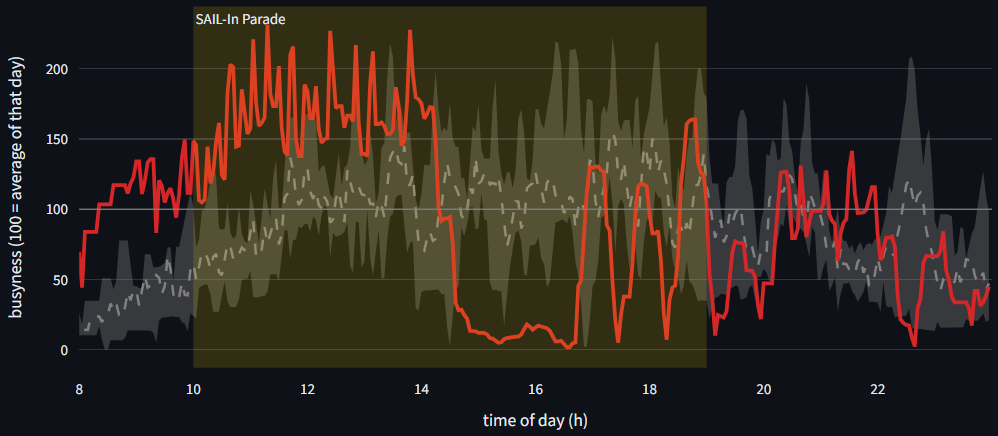

*Figure SQ3.2 – Ferry landing at NDSM on the same day.*

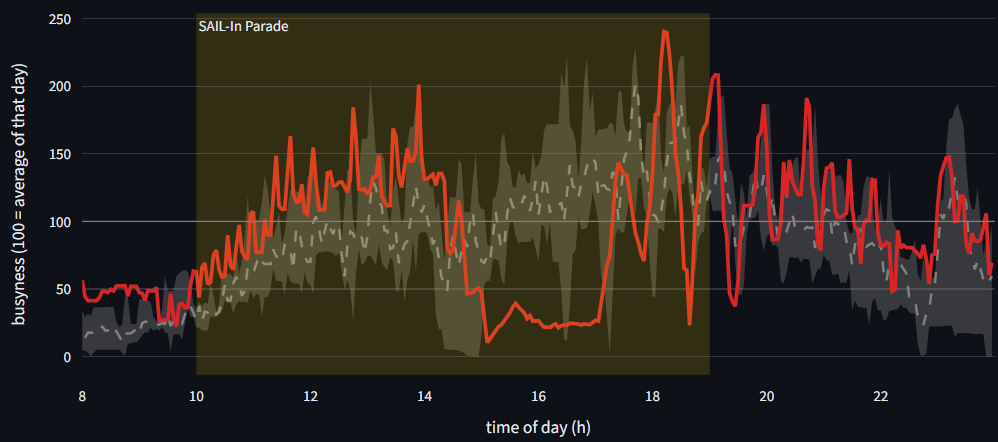

1. Before the ships arrived (10:00 to 14:30), the landing at Central Station was about twice as busy as on a normal SAIL day: visitors were crossing to NDSM to see the fleet come in.
2. While the parade passed (from about 14:45 to 17:00), both ends of the ferry dropped to almost no passengers, something no other day shows.
3. **After the parade**, people came back, and at around 18:15 NDSM reached its highest value of the whole week.

A broken sensor would not explain this: both landings dropped together, and not to exactly zero. The most likely explanation is that the ferry stopped while the ships sailed past. We did not find an official source that confirms it, so we report it as what the data suggest. For a crowd manager, this is as important as a peak: an event can also cut a route, and leave thousands of people waiting on one side of the IJ.

Some limitations

- **First and last day.** SAIL-In was on the first day and SAIL-Out on the last. Part of their effect may come from visitors arriving and leaving, which would happen on those days anyway.
- **People passing, not people present.** The sensors count people walking past. A quay full of spectators standing still can look quiet in the data.
- **Few days to compare.** Liked it was mentioend before, there is no week without SAIL, so a "normal" day means the median of the other four SAIL days, which were all busier than a usual day in Amsterdam.
- **Our own assumptions.** The zones linked to each event were chosen by us from the event locations (`data/external/event_zone_links.csv`). Different choices of zones will definetely give different numbers.

So, do SAIL events explain the peaks?

SAIL events explain part of the peaks, and it is the events on the water that do. Ship parades leave a measurable mark on the zones along the IJ, both as peaks before and after the parade and as gaps while it passes, as the ferry to NDSM shows. Events on land, such as the Crew Parade, disappear in the crowd that the city centre has every day.

# SQ4 – Do trains explain the peaks?

Visitors who come to SAIL by train arrive at Amsterdam Centraal. If trains drive the counts, the sensors around the station should get busier a few minutes after each arrival. We looked at the 13 sensors within about 400 m of the station: four on the IJboulevard behind it (GASA-01), five at the ferry landings (GVCV), one on Damrak in front of it (GACM-04) and three on the east side (GASA-02 and GASA-04). For each sensor we added up both walking directions and compared the count with the trains that arrived in the same 3 minutes.

We first compared the two over the day. If more trains brought the crowd, the busiest hours should also have the most trains. They do not: between 09:00 and 22:00 the number of trains hardly changes, while the counts more than triple.

In [1]:
import sys

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, "src")   # the modules in src/ import each other by their short names
from station_sensors import station_counts
from trains import train_counts
from train_effect import HOURS, daytime, next_minutes, people_after_trains

people = station_counts()                  # one column per sensor, NaN when the sensor was off
total = people.sum(axis=1, skipna=False)   # the 13 sensors together
trains = train_counts()                    # arrivals and departures at Amsterdam Centraal

hours = slice(HOURS[0], HOURS[1] - 1)
trains_per_hour = trains["arrivals"].groupby(trains.index.hour).sum().loc[hours] / 5   # 5 days
counts_per_hour = total.groupby(total.index.hour).mean().loc[hours] * 20               # 20 intervals per hour
print("Train arrivals, 20-24 August:", trains["arrivals"].sum())
print(f"Trains per hour, 09:00-22:00: {trains_per_hour.min():.0f} to {trains_per_hour.max():.0f}")
print(f"Counts per hour at the 13 sensors: {counts_per_hour.min():,.0f} at {counts_per_hour.idxmin()}:00, "
      f"{counts_per_hour.max():,.0f} at {counts_per_hour.idxmax()}:00")

Train arrivals, 20-24 August: 3844
Trains per hour, 09:00-22:00: 38 to 44
Counts per hour at the 13 sensors: 10,471 at 9:00, 37,844 at 17:00


So the daily peak does not come from more trains. A train could still add a short peak of its own, a few minutes long. To check this, we sorted the 1,300 three-minute intervals between 09:00 and 22:00 by the number of trains that arrived in them: 0 or 1, 2, 3, or 4 or more. For each group we took the pedestrians counted in the next 15 minutes, which leaves time to walk from the platform to the sensors. Raw counts would be misleading here: at night there are fewer trains and fewer people, so the two would rise together just because of the time of day. Instead, we compared each count with the average of the hour around it: +5% means 5% more people than usual for that time of day. Intervals in which a sensor was off (see SQ1) are left out.

                             IJboulevard  ferry landings  Damrak  east side  all 13 sensors
trains arrived in 3 minutes                                                                
0-1                                  0.2            -0.3    -0.3        0.0             0.2
2                                   -0.5            -1.1     0.3       -0.3            -0.4
3                                    0.5            -0.9    -0.1        0.0            -0.1
4 or more                            0.6            -0.3     0.7        0.6             0.5

Normal ups and downs of the 13 sensors in 15 minutes: about 6%


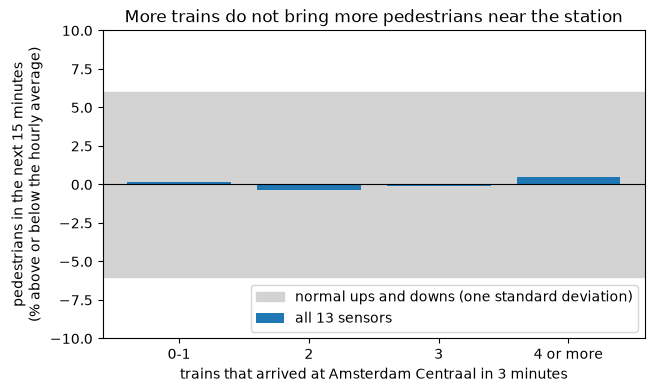

In [ ]:
areas = {"IJboulevard": "GASA-01", "ferry landings": "GVCV", "Damrak": "GACM",
         "east side": ("GASA-02", "GASA-04"), "all 13 sensors": "G"}   # every sensor name starts with G
by_area = pd.DataFrame({name: people.loc[:, people.columns.str.startswith(start)].sum(axis=1, skipna=False)
                        for name, start in areas.items()})
after_trains = people_after_trains(trains["arrivals"], by_area)
print(after_trains.round(1).to_string())

usual = next_minutes(total)[daytime(total.index)].std()   # how much a normal quarter of an hour moves
print(f"\nNormal ups and downs of the 13 sensors in 15 minutes: about {usual:.0f}%")

fig, ax = plt.subplots(figsize=(7, 4))
ax.axhspan(-usual, usual, color="lightgrey", label="normal ups and downs (one standard deviation)")
ax.bar(after_trains.index, after_trains["all 13 sensors"], color="tab:blue", label="all 13 sensors")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylim(-3, 3)
ax.set_xlabel("trains that arrived at Amsterdam Centraal in 3 minutes")
ax.set_ylabel("pedestrians in the next 15 minutes\n(% above or below the hourly average)")
ax.set_title("More trains do not bring more pedestrians near the station")
ax.legend(loc="lower right")
plt.show()

If trains brought the crowd, the bars would rise from left to right. They hardly move. After 4 or more trains the 13 sensors counted 0.5% more people than usual, and after 0 or 1 train 0.2% more. Per area the values stay between -1.1% and +0.7%. These differences are small next to the normal ups and downs of the counts: a quarter of an hour is typically about 6% above or below the hourly average (the grey band).

The effect is probably hidden because during the day a train arrives about every one and a half minutes, and only one interval in ten has no arrival at all. The passengers of one train mix with those of the next, so the sensors see a steady stream instead of separate waves. We also count trains, not passengers, and a full train weighs as much as an empty one.

Our answer to SQ4 is therefore no: train arrivals do not explain the peaks near Amsterdam Centraal, at least not in a way the counts can show. The daily peak happens while the number of trains stays the same, and an interval with many arrivals is not followed by more pedestrians. For the crowd manager, a sudden rise at the station sensors should not be read as a train that has just emptied, and the train layer of the dashboard gives context but no warning. A sharper test would need the number of passengers per train, which we did not have.

# SQ5 – Do vessels explain the peaks?

The subquestion three showed that the events that moved people are the water-events. In this subquestion we will look at the ships: SAIL brought more than 10,000 of them to the IJ, and the tall ships are what most visitors come to see. If ships attract crowds, the sensors along the water should be busier.

**How we looked at it.** The vessel data (AIS positions) was filtered to the ships of the SAIL fleet, by type and destination, and drawn on the map of the dashboard together with the sensors. For each day, the dashboard also counts how many different SAIL ships were seen ("The day in numbers", KPI).

*Figure SQ5.1 – Sensors (coloured by level of service) and SAIL ships (purple, last known position) on Wednesday 20 August at 14:03, while the SAIL-In fleet was approaching through the North Sea Canal.*

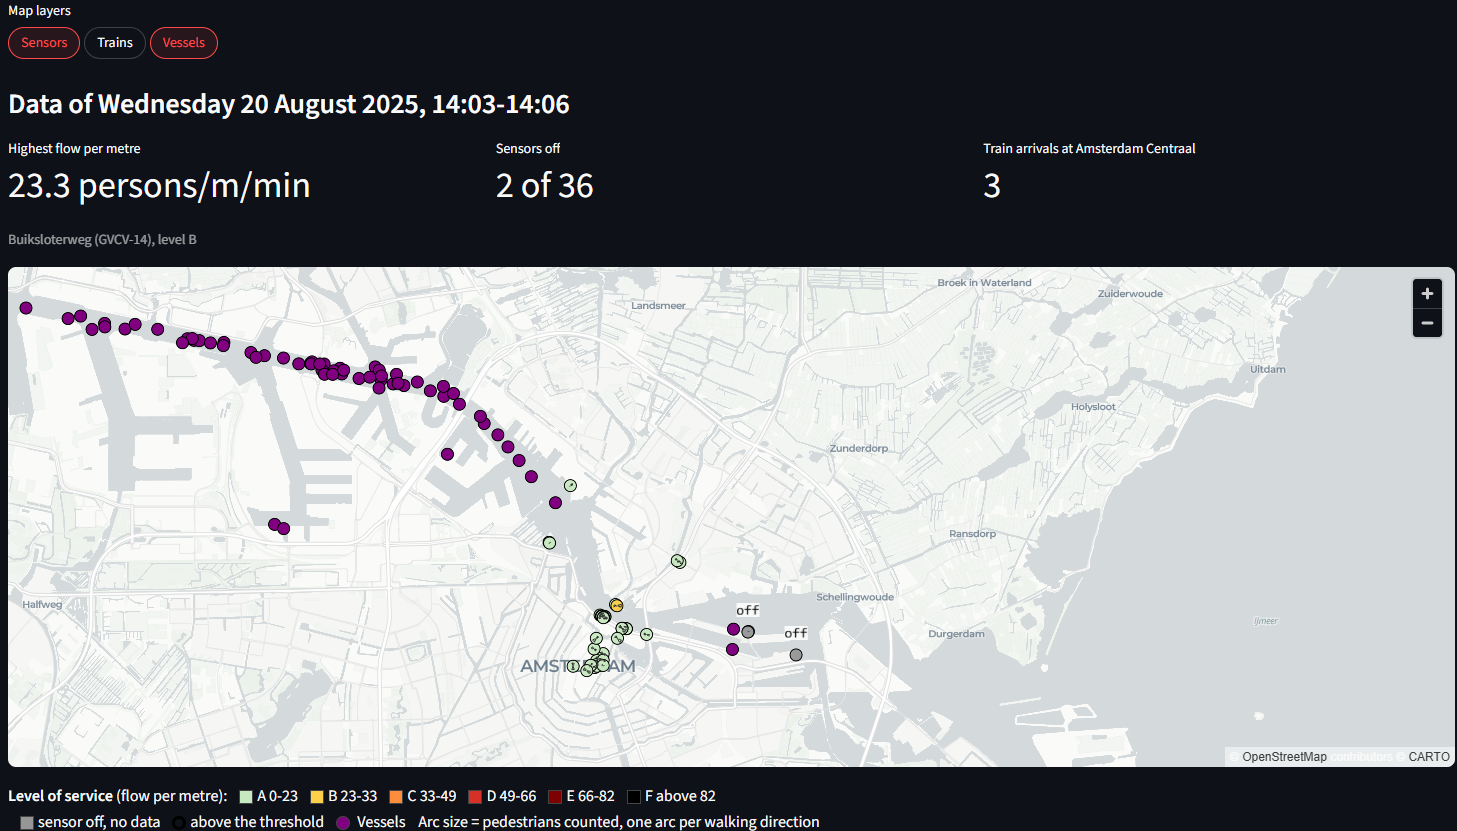

*Figure SQ5.2 – The same view at 16:03, while the fleet sailed through the IJ.*

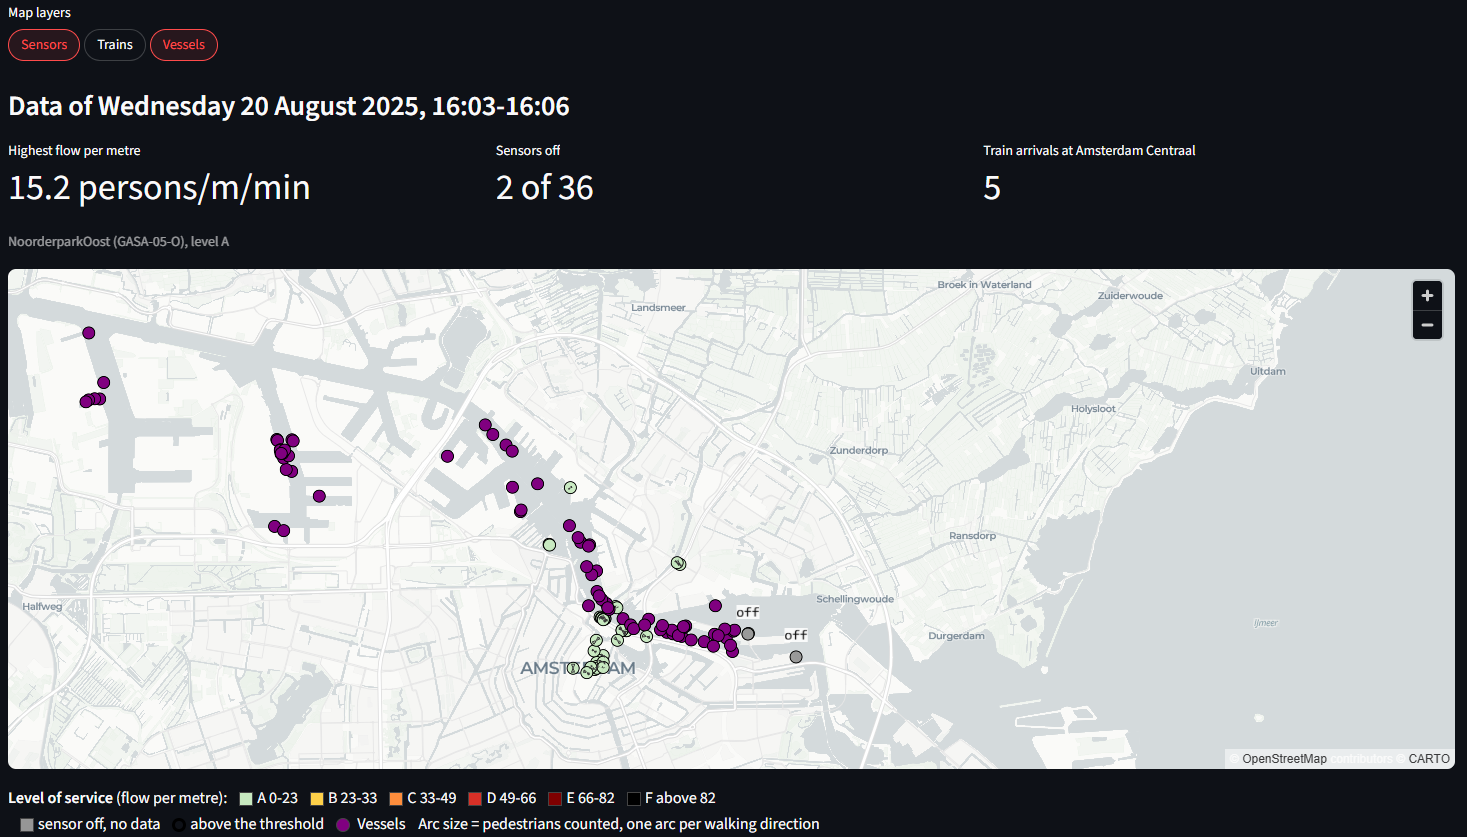

These two moments tell a lot:

- At 14:03 the fleet was still on its way in: a long line of ships in the North Sea Canal, with the first ones reaching the IJ near NDSM. The busiest place was a ferry landing, Buiksloterweg (23 persons/m/min, level B): visitors were crossing the water to see the fleet arrive.
- At 16:03 the fleet was on the IJ, in front of Central Station and along the eastern docks. All sensors had dropped to level A, and the highest flow (15 persons/m/min) was in Noorderpark, away from the water.

When the ships were on the IJ, the sensors along the water were quiet. This matches SQ3: at the same time, the ferry between Central Station and NDSM almost stopped carrying people. Visitors did not walk past the sensors, they stood on the quays to watch the ships, and standing people are not counted.

The number of SAIL ships seen per day was highest on the day of SAIL-In (85), when the fleet arrived, and stayed between 66 and 72 on the other days: most of the fleet stayed in Amsterdam for the whole event. The ships were a constant presence, while the pedestrian counts rose and fell during each day (SQ2).

| Day | SAIL ships seen |
|---|---|
| Wednesday 20 August | 85 |
| Thursday 21 August | 72 |
| Friday 22 August | 66 |
| Saturday 23 August | 68 |
| Sunday 24 August | 69 |

The vessels dont exactly explain the peaks. While the SAIL fleet sailed through the IJ, the sensors along the water were quiet: visitors stood still to watch, and the ferry to NDSM stopped. The ships shape the crowds in time rather than creating peaks themselves: people gather before the fleet arrives, wait while it passes, and move again afterwards, which is when the counts go up (SQ3). For a crowd manager, this means that the sensors underestimate the crowd exactly when the ships are on the IJ, and that the critical moment is the end of a parade, when everyone starts walking at once.

# Conclusion

We asked to what extent trains, vessels and SAIL events affected the pedestrian counts around the IJ during SAIL 2025. In short: the trains hardly did, the events on the water did, and the ships mostly changed when people walked rather than how many.

Before looking for causes, we checked the data. Most sensors could be trusted: GASA-06 at Azartplein counted almost nothing all week and GVCV-09 at Zeeburg often reported zero, but both are far from the centre (SQ1). The crowds were largest on Saturday 23 August, and on every day the counts peaked in the late afternoon, around 17:00. The highest flows per metre were measured at the ferry landings, up to 58.8 persons per metre per minute at NDSM on Friday evening. Even there, the flow reached level D of Fruin in only 20 of about 74,000 sensor intervals, and never level E or F (SQ2).

Trains arrived at Amsterdam Centraal about every one and a half minutes, at almost the same rate all day, while the counts near the station more than tripled between 09:00 and 17:00. In the 15 minutes after many arrivals, the sensors counted no more people than after few (SQ4). The SAIL programme did leave a mark, but only on the water: in 7 of the 18 event and zone pairs we tested, the event day was the most unusual of the five, and all 7 were ship parades (SQ3). The ships themselves did not create the peaks. While the fleet sailed through the IJ, the sensors along the water went quiet, because people stood still to watch and the ferry to NDSM almost stopped carrying passengers. The counts rose again when the parade was over (SQ3, SQ5).

For a crowd manager, this changes how the numbers should be read. A busy station sensor does not mean that a train has just emptied, and a quiet quay during a parade is not good news: the people are still there, they are just not walking. The critical moment is the end of a parade, when everyone starts moving at once, and the places to watch are the ferry landings. This is why the dashboard puts the sensors, the trains, the ships and the events on one map: a count only makes sense next to what is happening around it.

# Discussion

**What we expected and what we found.** We started from a simple picture: trains, ships and events bring people, so they should add peaks to the counts. Only the events fit this picture, and only those on the water. The trains did not add peaks we could see, and the ships did the opposite of what we expected: when they were on the IJ, the counts along the water went down. Of the three factors, the timing of the programme told us the most about the crowd. The levels of service point the same way. Even the busiest moments stayed far from level F of Fruin (1971), the level of a jammed walkway, so at the places with a sensor SAIL 2025 never came close to a dangerous crowd.

**What we missed: the ferries.** The ferry landings had the highest flows of the week, and all 20 intervals at level D were measured there. During SAIL-In, the ferry to NDSM almost stopped carrying people while the fleet passed. Yet the ferries were not one of our factors. Like trains, they bring people in waves, but we had no ferry timetables or passenger numbers, so we could not tell whether a peak at a landing came from a ferry arriving, from a ferry that did not run, or from visitors waiting for one. With those data, the ferries could be studied the same way as the trains in SQ4, and the stop during the parade could be confirmed.

**Limitations.**
- The sensors count people walking past, not people standing. A quay full of spectators can look empty in the data, which is the main reason the ships seem to lower the counts.
- There is no normal week to compare with. A "normal" day is the median of the other SAIL days, which were all busier than an ordinary day in Amsterdam, and SAIL-In and SAIL-Out fell on the first and the last day.
- We counted trains, not passengers, in steps of 3 minutes. With a train every one and a half minutes, there is little room to see the effect of a single train.
- Several choices are our own: the zones each event is linked to, the rule that marks a sensor as off (which also flags ferry landings at night, when no ferry runs), and the moderate alarm level of 35 persons/m/min. Fruin's levels were made for walkways in the 1970s, not for ferry landings where people arrive in groups.
- Our methods compare days and groups of intervals. They show where the counts change together with a factor, not that the factor caused the change, even if the research question uses the word "affecting".

**Next steps.** For the next SAIL in 2030, three kinds of data would help most: passenger numbers per train and per ferry, a normal week of counts from the crowd monitor of the City of Amsterdam to compare with, and sensors that measure density as well as flow, so that standing crowds become visible. Each of them could be added to the dashboard as an extra layer.

# References

- Helbing, D., & Mukerji, P. (2012). Crowd disasters as systemic failures: analysis of the Love Parade disaster. *EPJ Data Science*, 1(7).
- Sharma, A., McCloskey, B., Hui, D. S., et al. (2023). Global mass gathering events and deaths due to crowd surge, stampedes, crush and physical injuries – lessons from the Seoul Halloween and other disasters. *Travel Medicine and Infectious Disease*, 52, 102524.
- Daamen, W. (2026). SAIL2025 Design Challenges. Lecture slides, TIL4030 Research and Design Methods, TU Delft.
- Fruin, J. J. (1971). *Pedestrian planning and design*. Metropolitan Association of Urban Designers and Environmental Planners.
- Rijden de Treinen. Open train archive, https://www.rijdendetreinen.nl/en/open-data/train-archive
- SAIL Amsterdam Foundation (2025). SAIL Amsterdam 2025, programme and event locations, https://www.sail.nl

# Use of AI

We acknowledge the use of Claude (Anthropic, https://claude.ai) and Gemini in preparing this submission. We used it for the following purposes: explaining concepts, assisting with programming and debugging, refining language (grammar, clarity), providing feedback on draft or code, and guidance on the Git workflow (branches, commits and pull requests).

**Davide Pighin.** 🔴 

**Andrea Della Corte.** 🔴

**Daniele Bini.** 🔴

**José Roberto Cortes Camilo De Sales.** I used Claude for explaining concepts (methods I wanted to use for the analysis and the visualisations). For brainstorming complementing my ideas. Also used it to give me feedback on my drafted code following my instructions and requests, and to ensure that it followed the correct standards of coding (`src/flow.py`, `src/events.py`, `src/event_plots.py`, `src/event_impact.py`, `src/day_overview.py`) and to debug it. Transcribing the SAIL programme and collecting the event locations, also to refine the language, and as a guide for the Git workflow when I had doubts. I ran and tested all code based on the findings that I wanted to achieve, adapted it, and checked and interpreted the results myself.

**Mateo Gonzalez.** 🔴 

We confirm that we have critically reviewed and verified all AI-assisted content, that the submitted work reflects our own understanding, and that we take full responsibility for its accuracy and originality.